In [17]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt 
from warnings import filterwarnings 
filterwarnings("ignore")

In [5]:
df = pd.read_csv(r"C:\Users\deytu\Desktop\study\EXCELR\Assignment\Data and Docs\amazonreviews.tsv", sep = "\t")
df

,label,review
0,pos,Stuning even for the non-gamer: This sound tra...
1,pos,The best soundtrack ever to anything.: I'm rea...
2,pos,Amazing!: This soundtrack is my favorite music...
3,pos,Excellent Soundtrack: I truly like this soundt...
4,pos,"Remember, Pull Your Jaw Off The Floor After He..."
...,...,...
9995,pos,A revelation of life in small town America in ...
9996,pos,Great biography of a very interesting journali...
9997,neg,Interesting Subject; Poor Presentation: You'd ...
9998,neg,Don't buy: The box looked used and it is obvio...


In [6]:

print("Dataset shape:", df.shape)
display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nSentiment distribution:")
print(df["label"].value_counts())

Dataset shape: (10000, 2)


,label,review
0,pos,Stuning even for the non-gamer: This sound tra...
1,pos,The best soundtrack ever to anything.: I'm rea...
2,pos,Amazing!: This soundtrack is my favorite music...
3,pos,Excellent Soundtrack: I truly like this soundt...
4,pos,"Remember, Pull Your Jaw Off The Floor After He..."



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   label   10000 non-null  object
 1   review  10000 non-null  object
dtypes: object(2)
memory usage: 156.4+ KB

Missing values:
label     0
review    0
dtype: int64

Duplicate rows: 0

Sentiment distribution:
label
neg    5097
pos    4903
Name: count, dtype: int64


### Observations

1. **Dataset structure:** The dataset contains 10,000 rows and two columns: `label` and `review`. Both columns have the object data type, which is appropriate for categorical sentiment labels and textual reviews.

2. **Missing values:** No missing values were found in either column. Therefore, missing-value imputation is not required.

3. **Duplicate records:** No exact duplicate rows were identified during the initial inspection, so duplicate removal is not necessary at this stage.

4. **Sentiment distribution:** The dataset contains 5,097 negative reviews (50.97%) and 4,903 positive reviews (49.03%). The difference between the two classes is small, indicating that the dataset is nearly balanced.

5. **Modeling implications:** Since the classes are nearly balanced, stratified train-test splitting can preserve their proportions. Accuracy can be used alongside precision, recall, F1-score, and a confusion matrix to evaluate model performance.

**Conclusion:** The dataset is structurally complete and suitable for further exploratory analysis, text preprocessing, and sentiment classification.

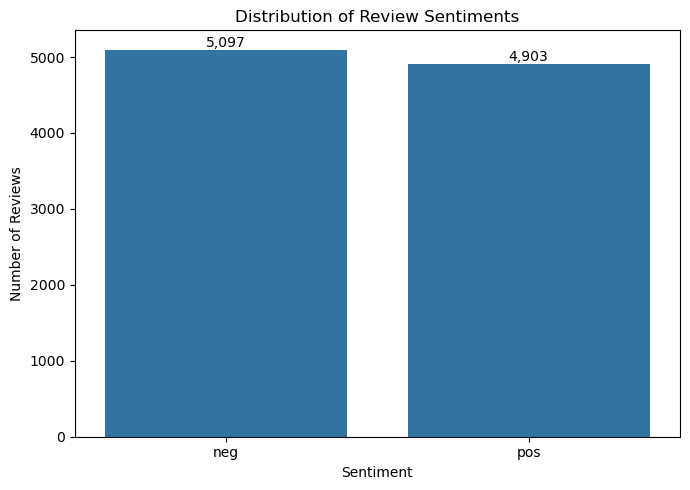

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="label",
    order=["neg", "pos"]
)

ax.set_title("Distribution of Review Sentiments")
ax.set_xlabel("Sentiment")
ax.set_ylabel("Number of Reviews")

for bar in ax.patches:
    ax.annotate(
        f"{int(bar.get_height()):,}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

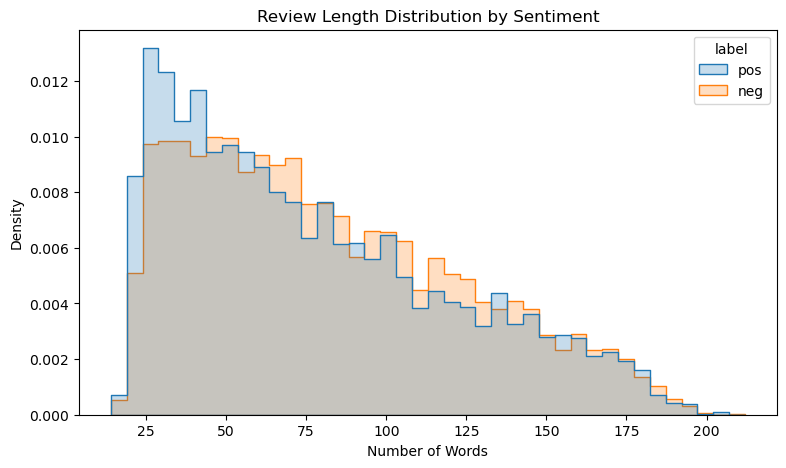

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
neg,5097.0,81.744556,42.487401,15.0,47.0,74.0,112.0,212.0
pos,4903.0,77.274934,43.460589,14.0,40.0,68.0,106.0,207.0


In [8]:
df["word_count"] = df["review"].str.split().str.len()

plt.figure(figsize=(9, 5))
sns.histplot(
    data=df,
    x="word_count",
    hue="label",
    bins=40,
    element="step",
    stat="density",
    common_norm=False
)
plt.title("Review Length Distribution by Sentiment")
plt.xlabel("Number of Words")
plt.show()

display(df.groupby("label")["word_count"].describe())

In [9]:
%pip install wordcloud

Note: you may need to restart the kernel to use updated packages.


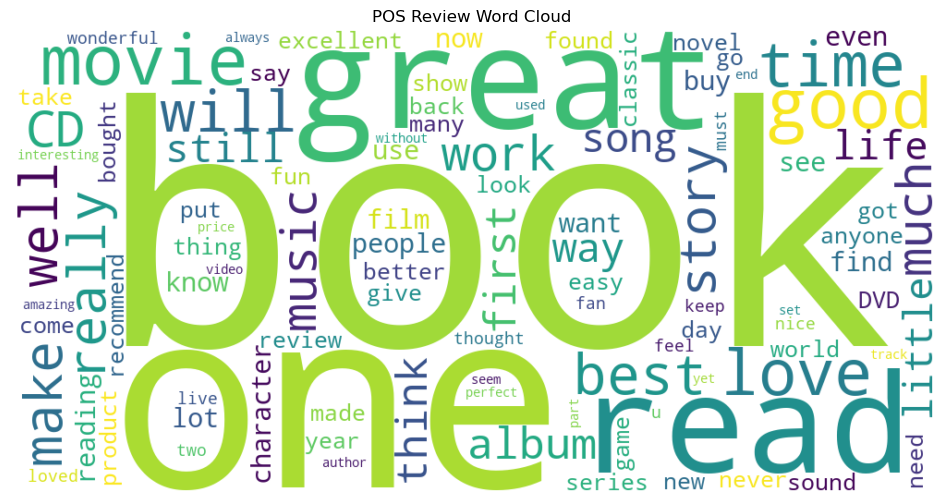

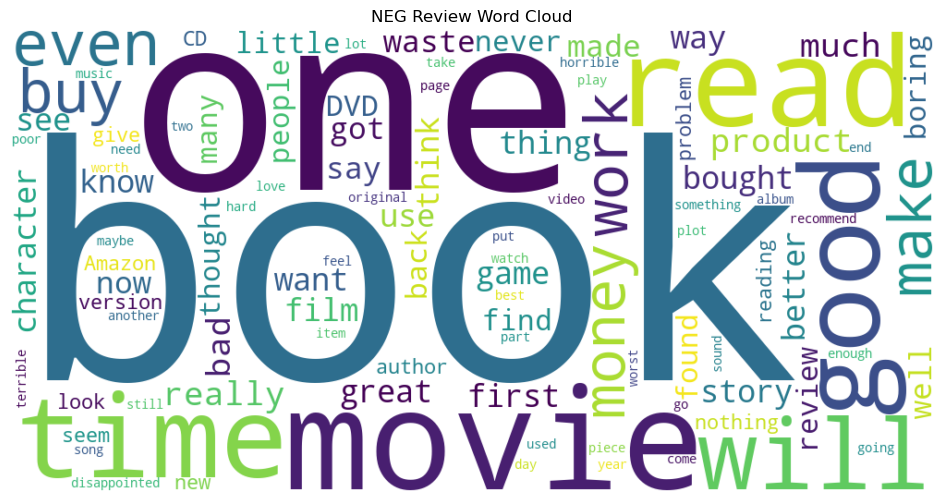

In [10]:
from wordcloud import WordCloud

for sentiment in ["pos", "neg"]:
    text = " ".join(df.loc[df["label"] == sentiment, "review"])

    wordcloud = WordCloud(
        width=1000,
        height=500,
        background_color="white",
        max_words=100
    ).generate(text)

    plt.figure(figsize=(12, 6))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title(f"{sentiment.upper()} Review Word Cloud")
    plt.show()

### Observations

1. **Average review length:** Negative reviews have an average length of approximately 81.74 words, compared with 77.27 words for positive reviews. This suggests that negative reviews are slightly longer on average.

2. **Median review length:** The median length is 74 words for negative reviews and 68 words for positive reviews. This indicates that the typical negative review is somewhat longer than the typical positive review.

3. **Variability:** Both classes show considerable variation in review length, with standard deviations of approximately 42–43 words. This indicates that customers provide reviews of varying detail regardless of sentiment.

4. **Distribution and range:** Negative reviews range from 15 to 212 words, while positive reviews range from 14 to 207 words. The upper quartile values are 112 words for negative reviews and 106 words for positive reviews, showing a similar pattern of slightly longer negative reviews.

5. **Implications for sentiment analysis:** Review length may provide some contextual information, but it is not sufficient to determine sentiment. The classification models should primarily learn linguistic patterns and sentiment-bearing phrases using TF-IDF features.

**Conclusion:** Negative reviews tend to be slightly longer than positive reviews in this dataset, based on both the mean and median. However, these descriptive statistics alone do not establish whether the difference is statistically significant.

In [12]:
#### text pre proccesing
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r"<[^>]+>", " ", text)  # Remove HTML tags
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_review"] = df["review"].apply(clean_text)

display(df[["review", "clean_review", "label"]].head())

,review,clean_review,label
0,Stuning even for the non-gamer: This sound tra...,stuning even for the non gamer this sound trac...,pos
1,The best soundtrack ever to anything.: I'm rea...,the best soundtrack ever to anything i m readi...,pos
2,Amazing!: This soundtrack is my favorite music...,amazing this soundtrack is my favorite music o...,pos
3,Excellent Soundtrack: I truly like this soundt...,excellent soundtrack i truly like this soundtr...,pos
4,"Remember, Pull Your Jaw Off The Floor After He...",remember pull your jaw off the floor after hea...,pos


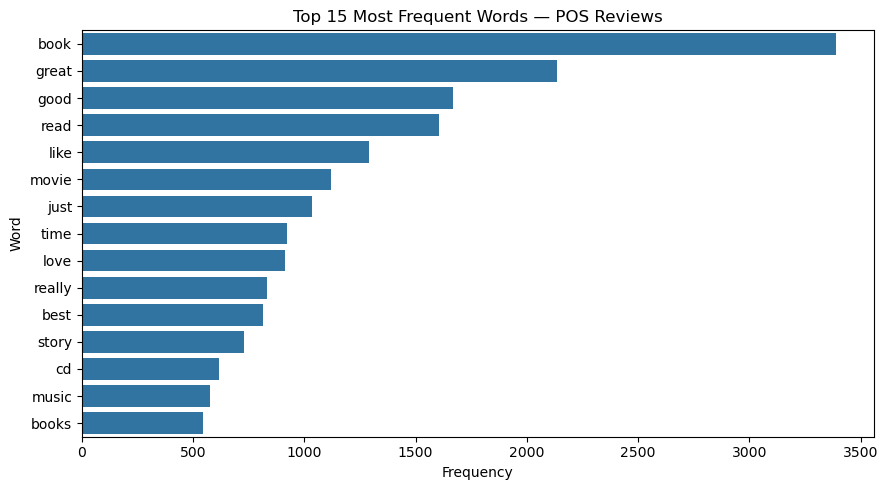

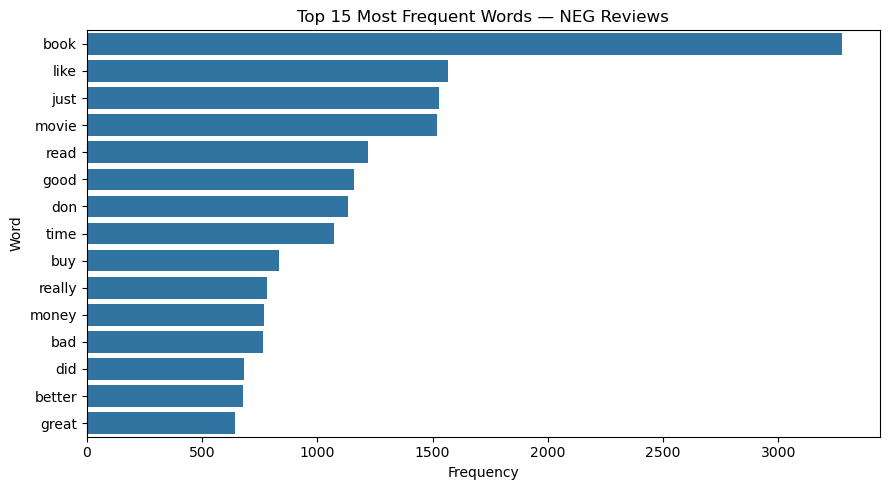

In [13]:
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

for sentiment in ["pos", "neg"]:
    text = df.loc[df["label"] == sentiment, "clean_review"]

    vectorizer = CountVectorizer(
        stop_words="english",
        max_features=15
    )

    word_matrix = vectorizer.fit_transform(text)
    word_counts = pd.DataFrame({
        "word": vectorizer.get_feature_names_out(),
        "frequency": word_matrix.sum(axis=0).A1
    }).sort_values("frequency", ascending=False)

    plt.figure(figsize=(9, 5))
    sns.barplot(
        data=word_counts,
        x="frequency",
        y="word"
    )
    plt.title(f"Top 15 Most Frequent Words — {sentiment.upper()} Reviews")
    plt.xlabel("Frequency")
    plt.ylabel("Word")
    plt.tight_layout()
    plt.show()

In [ ]:
###Model building

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

X = df["clean_review"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Multinomial Naive Bayes": MultinomialNB(),
    "Linear SVM": LinearSVC()
}

results = []
trained_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=30000,
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, pos_label="neg", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, pos_label="neg", zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, pos_label="neg", zero_division=0
        )
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results).sort_values(
    by="F1-score", ascending=False
)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score
2,Linear SVM,0.8755,0.8745,0.8822,0.8784
1,Multinomial Naive Bayes,0.8635,0.8435,0.8989,0.8703
0,Logistic Regression,0.8615,0.8581,0.8724,0.8652


### Observations

1. **Linear SVM:** Linear Support Vector Machine achieved the highest accuracy of **87.55%** and F1-score of **0.8784** among the three models. Its precision was 0.8745 and recall was 0.8822, indicating a relatively balanced performance in identifying negative reviews.

2. **Multinomial Naive Bayes:** This model achieved an accuracy of **86.35%** and the highest recall of **0.8989**. It identifies a larger proportion of actual negative reviews than the other models, although its precision of 0.8435 indicates more false-positive negative predictions.

3. **Logistic Regression:** Logistic Regression achieved an accuracy of **86.15%** and an F1-score of **0.8652**. Its precision of 0.8581 and recall of 0.8724 indicate reasonably balanced performance, although its overall metrics are slightly lower than those of Linear SVM.

4. **Comparison of F1-scores:** Linear SVM obtained the highest F1-score (0.8784), followed by Multinomial Naive Bayes (0.8703) and Logistic Regression (0.8652). This suggests that Linear SVM provides the best balance of precision and recall for the evaluated negative-review class.

5. **Business implications:** Linear SVM offers a balanced approach to identifying negative customer feedback, while Naive Bayes may be useful when detecting as many negative reviews as possible is a priority. The final choice should consider the relative cost of missed complaints versus incorrectly flagged positive reviews.

**Conclusion:** Linear SVM achieved the strongest overall results among the three tested models on the current test set. However, cross-validation and further error analysis are needed to assess the consistency of its performance before considering deployment.

              precision    recall  f1-score   support

    Negative       0.87      0.88      0.88      1019
    Positive       0.88      0.87      0.87       981

    accuracy                           0.88      2000
   macro avg       0.88      0.88      0.88      2000
weighted avg       0.88      0.88      0.88      2000



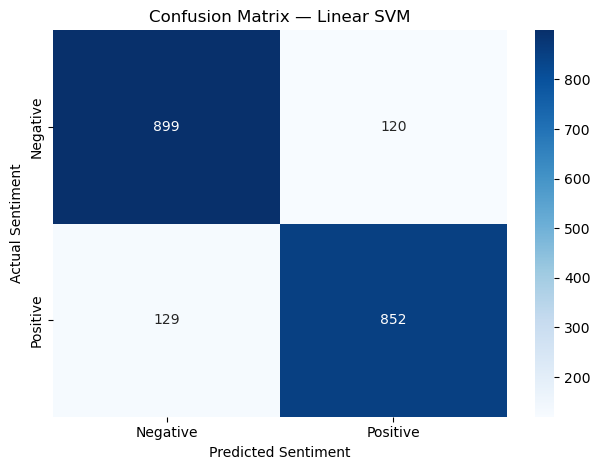

In [15]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

svm_model = trained_models["Linear SVM"]
y_pred_svm = svm_model.predict(X_test)

print(classification_report(
    y_test,
    y_pred_svm,
    target_names=["Negative", "Positive"],
    labels=["neg", "pos"]
))

cm = confusion_matrix(
    y_test,
    y_pred_svm,
    labels=["neg", "pos"]
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("Confusion Matrix — Linear SVM")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.tight_layout()
plt.show()

### Observations

1. **Overall accuracy:** Linear SVM achieved an accuracy of approximately **87.55%**, correctly classifying 1,751 out of 2,000 test reviews.

2. **Negative review classification:** Out of 1,019 actual negative reviews, the model correctly identified 899 and misclassified 120 as positive. The negative-class recall is approximately **88.22%**, indicating that the model detects most negative reviews.

3. **Positive review classification:** Out of 981 actual positive reviews, 852 were correctly classified, while 129 were incorrectly predicted as negative. The positive-class recall is approximately **86.85%**.

4. **False negatives in complaint detection:** The 120 negative reviews classified as positive are particularly important for the business problem. These reviews represent potential customer complaints that could go unnoticed by an automated monitoring system.

5. **Balanced performance:** The classification report shows precision, recall, and F1-scores of approximately 0.87–0.88 for both sentiment classes. The macro-average F1-score is approximately 0.88, indicating reasonably balanced classification performance across positive and negative reviews.

**Conclusion:** Linear SVM demonstrates effective sentiment classification, correctly predicting 1,751 of the 2,000 test reviews. However, further improvements should focus on reducing negative reviews incorrectly classified as positive, since missing customer complaints may delay corrective action.